# Room Style Transfer Assistant
### AI-Powered Interior Design Transformation Using Image-to-Image Diffusion

## Project Description

The Room Style Transfer Assistant is an AI-powered application that transforms room images into different interior design styles using Image-to-Image Diffusion Models.

The system takes an input image of a room and a text prompt describing the desired interior design style. It then generates a new image that reflects the requested style while attempting to preserve the original room structure and layout.

### Project Objectives
- Apply Image-to-Image Diffusion techniques.
- Transform room images into different interior design styles.
- Understand how text prompts guide image generation.
- Build an interactive AI-powered application.

### Technologies
- Python
- Google Colab
- Stable Diffusion
- Hugging Face Diffusers
- PyTorch
- Gradio

## **Import Libraries**

In [ ]:
import torch
import diffusers
import transformers
import PIL
import matplotlib.pyplot as plt

## GPU Availability Check

In [ ]:
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

GPU Available: True
GPU Name: Tesla T4


## Install Required Libraries

In [ ]:
!pip install -q diffusers transformers accelerate safetensors gradio

In [ ]:
import diffusers
import transformers
import gradio

print("Libraries installed successfully!")
print("Diffusers version:", diffusers.__version__)

Libraries installed successfully!
Diffusers version: 0.42.1


## Load Stable Diffusion Image-to-Image Model

In [ ]:
import torch
from diffusers import StableDiffusionImg2ImgPipeline

model_id = "sd-legacy/stable-diffusion-v1-5"

pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)

pipe = pipe.to("cuda")

print("Stable Diffusion model loaded successfully!")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Stable Diffusion model loaded successfully!


## Upload Input Room Image

Saving photo-1615874959474-d609969a20ed.avif to photo-1615874959474-d609969a20ed.avif


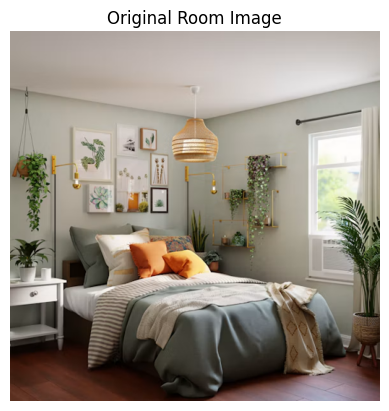

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded))

init_image = Image.open(image_path).convert("RGB")

init_image = init_image.resize((512, 512))

plt.imshow(init_image)
plt.axis("off")
plt.title("Original Room Image")
plt.show()

## Generate New Room Design Using Image-to-Image Diffusion

In [ ]:
prompt = """
Transform this bedroom into a modern minimalist bedroom.
Use elegant neutral colors, modern furniture,
soft natural lighting, and a clean interior design.
Preserve the original room structure and layout.
"""

negative_prompt = """
blurry, low quality, distorted furniture,
deformed objects, unrealistic architecture
"""

  0%|          | 0/16 [00:00<?, ?it/s]

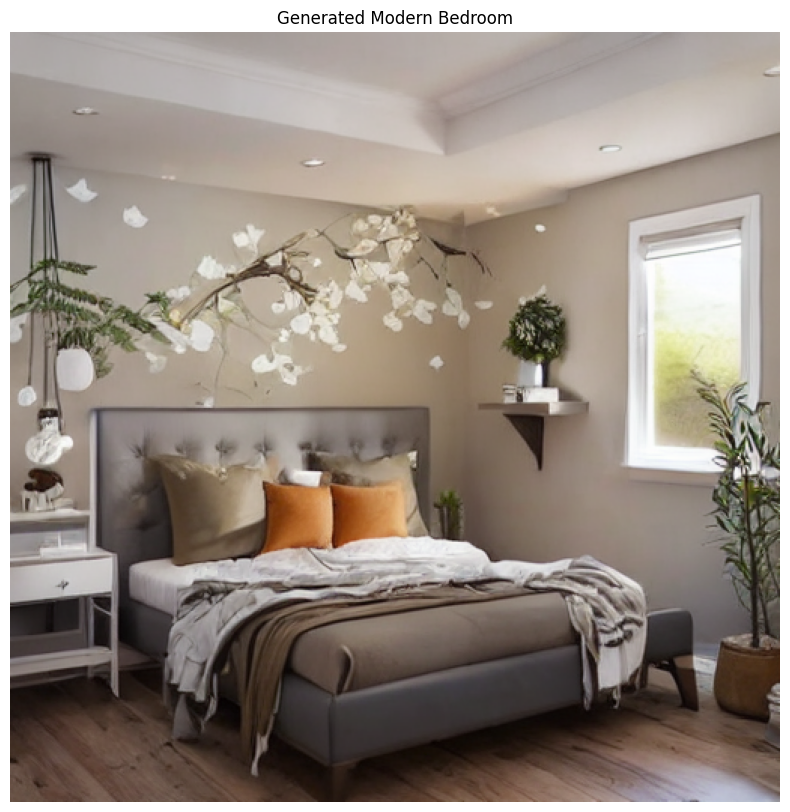

In [ ]:
result = pipe(
    prompt=prompt,
    image=init_image,
    strength=0.65,
    guidance_scale=7.5,
    num_inference_steps=25,
    negative_prompt=negative_prompt
).images[0]

plt.figure(figsize=(10, 10))
plt.imshow(result)
plt.axis("off")
plt.title("Generated Modern Bedroom")
plt.show()

## Compare Original and Generated Images

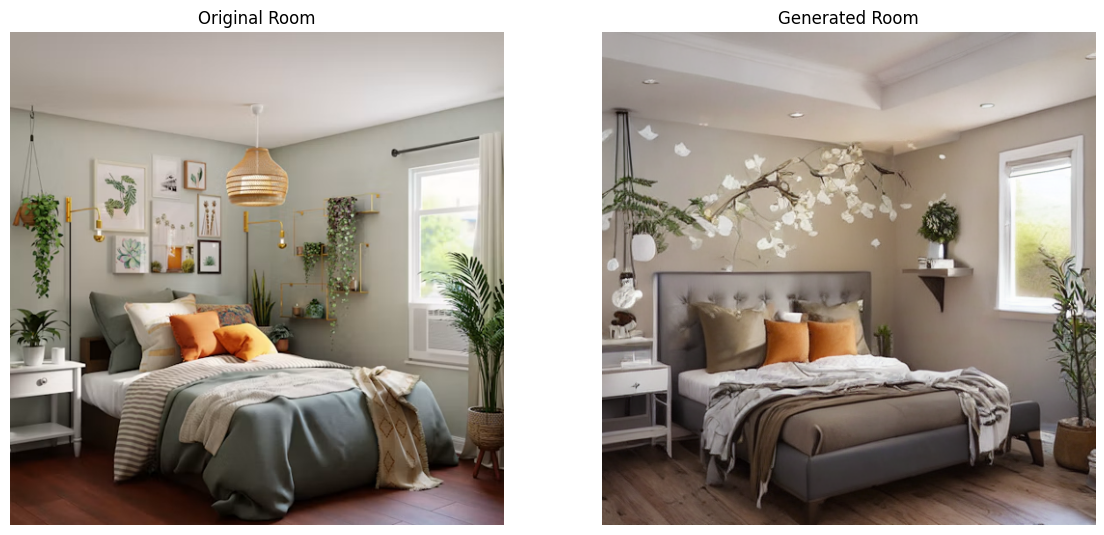

In [ ]:
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(init_image)
plt.title("Original Room")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result)
plt.title("Generated Room")
plt.axis("off")

plt.show()

In [ ]:
result.save("generated_modern_bedroom.png")

print("Image saved successfully!")

Image saved successfully!


## Build Interactive User Interface Using Gradio

In [ ]:
import gradio as gr
from PIL import Image

# Available interior design styles
styles = {
    "Modern": "modern minimalist interior design, elegant furniture, neutral colors",
    "Scandinavian": "Scandinavian interior design, natural wood, bright colors, cozy atmosphere",
    "Luxury": "luxury interior design, elegant furniture, marble, sophisticated decoration",
    "Bohemian": "bohemian interior design, colorful textiles, natural materials, artistic decoration"
}

# Image generation function
def generate_design(image, style, extra_prompt, strength, guidance, steps):

    if image is None:
        raise gr.Error("Please upload a room image first.")

    image = image.convert("RGB")
    image = image.resize((512, 512))

    prompt = f"""
    Transform this room into {styles[style]}.
    {extra_prompt}
    Preserve the original room structure and layout.
    High quality interior photography.
    """

    negative_prompt = """
    blurry, low quality, distorted furniture,
    deformed objects, unrealistic architecture
    """

    result = pipe(
        prompt=prompt,
        image=image,
        strength=strength,
        guidance_scale=guidance,
        num_inference_steps=int(steps),
        negative_prompt=negative_prompt
    ).images[0]

    return result


# Create Gradio interface
with gr.Blocks(title="Room Style Transfer Assistant") as demo:

    gr.Markdown(
        """
        # Room Style Transfer Assistant
        ### AI-Powered Interior Design Transformation

        Upload your room image and transform it
        into your favorite interior design style!
        """
    )

    with gr.Row():

        with gr.Column():
            input_image = gr.Image(
                type="pil",
                label="Upload Your Room Image"
            )

            style = gr.Dropdown(
                choices=list(styles.keys()),
                value="Modern",
                label="Choose Interior Design Style"
            )

            extra_prompt = gr.Textbox(
                label="Additional Instructions",
                placeholder="Example: Add indoor plants and warm lighting"
            )

            strength = gr.Slider(
                minimum=0.3,
                maximum=0.9,
                value=0.65,
                step=0.05,
                label="Transformation Strength"
            )

            guidance = gr.Slider(
                minimum=1,
                maximum=15,
                value=7.5,
                step=0.5,
                label="Prompt Guidance"
            )

            steps = gr.Slider(
                minimum=15,
                maximum=40,
                value=25,
                step=1,
                label="Generation Steps"
            )

            generate_btn = gr.Button(
                "Generate Design",
                variant="primary"
            )

        with gr.Column():
            output_image = gr.Image(
                label="Generated Room Design"
            )

    generate_btn.click(
        fn=generate_design,
        inputs=[
            input_image,
            style,
            extra_prompt,
            strength,
            guidance,
            steps
        ],
        outputs=output_image
    )

# Launch application
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f1813ae967e3cf1e2f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Conclusion

Through this project, I successfully designed and implemented an AI-powered **Room Style Transfer Assistant** using Image-to-Image Diffusion technology and a pre-trained Stable Diffusion model.

The primary objective was to explore the capabilities of Generative AI in transforming interior room images into different design styles while maintaining the overall visual structure of the original image.

I developed an end-to-end workflow using Python, PyTorch, Hugging Face Diffusers, and Gradio. The implementation included loading a pre-trained diffusion model, processing input images, generating redesigned interiors through text prompts, and developing an interactive interface that enables users to customize the transformation process.

This project provided me with valuable hands-on experience in applying Deep Learning and Computer Vision concepts to a practical real-world application. It also strengthened my understanding of diffusion models, prompt engineering, image generation, and AI application development.

### Limitations and Future Work

Although the application successfully demonstrates the Image-to-Image transformation process, there are opportunities for further improvement, including:

- Enhancing the visual quality and consistency of generated images.
- Improving the preservation of the original room geometry and furniture arrangement.
- Expanding the available interior design styles.
- Optimizing model performance and generation time.
- Enhancing the interactive interface and overall user experience.

### Final Remarks

This project represents a practical application of Generative AI in interior design, demonstrating how pre-trained diffusion models can transform ordinary room images into creative design alternatives.

It also marks an important step in my practical learning journey in Artificial Intelligence, particularly in Computer Vision and Deep Learning.